# Week 6: Brain-Tumour MRI Classification (No Tumour vs Tumour) with ResNet-18

**Author**: Muhammad Umar Khan.  
**Date**:  24 October, 2026  
**Course**: Introduction to Applied AI

**What this notebook does, end to end**

1. Index the MRI images and merge 4 folders into 2 classes.
2. Inspect the data, remove exact duplicates, and build leak-free train / validation / test splits.
3. Fine-tune an ImageNet-pretrained ResNet-18 with class-weighted cross-entropy.
4. Evaluate with macro-F1, sensitivity, specificity and PPV, and choose a threshold for a target recall.
5. Explain predictions with Grad-CAM and save the model.

All numbers quoted in the notes below are the values printed by the cells in this notebook. The answers to the six review questions are in the last cell.

## 1. Configuration

This is the only cell that has to change for a different dataset.

| Setting | Value | Meaning |
|---|---|---|
| `DATA_ROOT` / `TRAIN_DIR` | Kaggle brain-tumor-mri-dataset | folder whose sub-folders are the classes (glioma, meningioma, notumor, pituitary) |
| `TEST_DIR` | `None` | there is no separate test folder, so the code carves a test set out of the data |
| `GRAYSCALE` | `True` | MRI scans are grey-scale (the folder mixes L / RGB / RGBA files) |
| `IMG_SIZE` | 224 | input side length expected by ResNet-18 |
| `BACKBONE` | `resnet18` | pretrained network used as feature extractor |
| `GROUP_PATTERN` | `None` | file names (`Te-gl_1.jpg`, `Tr-pi_984.jpg`) contain no patient id, so every image is its own group |
| `BINARY` | `True` | merge the 4 folders into **no_tumor** vs **tumor** |
| `NORMAL_KEYWORD` | `'notumor'` | a folder whose name contains this is the healthy class |
| `POSITIVE` | `'tumor'` | the class that must not be missed |
| `TARGET_RECALL` | 0.95 | minimum sensitivity required when the decision threshold is chosen |

**Binary label rule**

$$
\text{label}=\begin{cases}\text{no\_tumor} & \text{if 'notumor' is in the folder name}\\ \text{tumor} & \text{otherwise (glioma, meningioma, pituitary)}\end{cases}
$$

In [1]:
# ============ CHANGE ONLY THIS CELL FOR YOUR OWN DATASET ============
DATA_ROOT = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset'   # folder with the 4 class folders
TRAIN_DIR = DATA_ROOT        # folder whose subfolders are the class folders (glioma, meningioma, notumor, pituitary)
TEST_DIR = None              # no separate test folder -> the code carves a test set
GRAYSCALE = True             # MRI scans are grey-scale (the folder mixes L / RGB / RGBA files)
IMG_SIZE = 224
BACKBONE = 'resnet18'
# File names look like 'Te-gl_1.jpg' / 'Tr-pi_984.jpg': there is no patient id in the name,
# so no grouping is possible -> every image is its own group.
GROUP_PATTERN = None
BINARY = True                # True: merge the 4 folders into 'no_tumor' vs 'tumor'
NORMAL_KEYWORD = 'notumor'   # a folder whose name contains this is the healthy class
NORMAL_LABEL = 'no_tumor'
POSITIVE = 'tumor'           # the class that must not be missed
TARGET_RECALL = 0.95
# ======================================================================


## 2. Imports and Reproducibility

Loads the libraries (PyTorch / torchvision for the model, scikit-learn for splitting and metrics, PIL for images, matplotlib for plots).

- **Seeds:** `torch.manual_seed(42)` and `np.random.seed(42)` make weight initialisation, shuffling and splits repeatable.
- **Device:** the code picks the GPU if one exists. The printed result is `Device: cpu`, so training is slow (roughly 350 to 460 s per epoch in the training cell).

In [2]:
import os
import re
import time
import copy
import hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms, models
from sklearn.model_selection import StratifiedGroupKFold, train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score,
                             roc_auc_score, roc_curve)

torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cpu


## 3. Indexing the Dataset and Checking Class Balance

`find_class_dirs` walks the folder and returns every sub-folder that directly contains images. `index_folder` builds a table with one row per image (path, label, original class folder, file name, group id). Because `GROUP_PATTERN = None`, **group = file name**, so each image is its own group.

**Counts printed by the cell**

| Original folder | Images | Merged label |
|---|---|---|
| glioma | 1800 | tumor |
| meningioma | 1800 | tumor |
| pituitary | 1800 | tumor |
| notumor | 1800 | no_tumor |

- no_tumor = 1800, tumor = 1800 + 1800 + 1800 = 5400, total = 7200

**Imbalance ratio**

$$
\text{ratio}=\frac{n_{\max}}{n_{\min}}=\frac{5400}{1800}=3.0
$$

**Tumour prevalence in the raw data**

$$
\frac{5400}{7200}=0.75=75\%
$$

**Images per group**

$$
\frac{7200\ \text{images}}{7200\ \text{groups}}=1.00
$$

A value of 1.00 means the file names give no way to keep images of the same patient together, so patient-level splitting is impossible. This is why the later duplicate checks matter.

In [3]:
IMG_EXT = ('.jpg', '.jpeg', '.png', '.bmp', '.tif')

def find_class_dirs(folder):
    """Return every sub-folder that directly contains images (= a class folder).
    Works whether the class folders sit directly in `folder` or one/two levels deeper
    (e.g. Kaggle's  <dataset>/<subfolder>/<class>/...)."""
    if not os.path.isdir(folder):
        raise FileNotFoundError(
            f'{folder} does not exist. Attach the dataset via "Add Input" in the Kaggle '
            f'sidebar, then copy its real path and set DATA_ROOT in the config cell.')
    dirs = []
    for root, subdirs, files in os.walk(folder):
        if any(f.lower().endswith(IMG_EXT) for f in files):
            dirs.append(root)
    if not dirs:
        raise FileNotFoundError(
            f'No images found under {folder}. Contents: {os.listdir(folder)[:10]}. '
            f'Set DATA_ROOT/TRAIN_DIR to the folder that holds the class folders.')
    return sorted(dirs)

def index_folder(folder):
    """One row per image: path, label, original class folder, file name, group id."""
    rows = []
    for cdir in find_class_dirs(folder):
        cls = os.path.basename(cdir)
        for f in sorted(os.listdir(cdir)):
            if f.lower().endswith(IMG_EXT):
                if BINARY:
                    label = NORMAL_LABEL if NORMAL_KEYWORD in cls.lower() else POSITIVE
                else:
                    label = cls
                rows.append({'path': os.path.join(cdir, f), 'label': label,
                             'orig_class': cls, 'file': f})
    df = pd.DataFrame(rows)
    assert len(classes_found := df['label'].unique()) >= 2 or not BINARY, \
        f'Only one class found {list(classes_found)}: check NORMAL_KEYWORD / folder names'
    if GROUP_PATTERN:
        m = df['file'].str.extract(GROUP_PATTERN, expand=False)
        df['group'] = m.fillna(df['file'])          # no match: its own group
    else:
        df['group'] = df['file']
    return df

train_df = index_folder(TRAIN_DIR)
test_df = index_folder(TEST_DIR) if TEST_DIR else None
classes = sorted(train_df['label'].unique())

counts = train_df['label'].value_counts().reindex(classes)
print(counts.to_string())
print(f'Imbalance ratio (max / min): {counts.max() / counts.min():.1f}')
print(f'Images per group: {len(train_df) / train_df.group.nunique():.2f}')
print('\nOriginal class folders:')
print(train_df['orig_class'].value_counts().to_string())
print('\nGroup regex check:')
print(train_df[['file', 'group']].head(10).to_string())

label
no_tumor    1800
tumor       5400
Imbalance ratio (max / min): 3.0
Images per group: 1.00

Original class folders:
orig_class
glioma        1800
meningioma    1800
notumor       1800
pituitary     1800

Group regex check:
            file          group
0    Te-gl_1.jpg    Te-gl_1.jpg
1   Te-gl_10.jpg   Te-gl_10.jpg
2  Te-gl_100.jpg  Te-gl_100.jpg
3  Te-gl_101.jpg  Te-gl_101.jpg
4  Te-gl_102.jpg  Te-gl_102.jpg
5  Te-gl_103.jpg  Te-gl_103.jpg
6  Te-gl_104.jpg  Te-gl_104.jpg
7  Te-gl_105.jpg  Te-gl_105.jpg
8  Te-gl_106.jpg  Te-gl_106.jpg
9  Te-gl_107.jpg  Te-gl_107.jpg


## 4. Inspecting Image Sizes, Colour Modes and Samples

A random sample of 300 images is opened to look at its properties, then 5 random images per class are plotted.

**Printed results (300-image sample)**

| | Width (px) | Height (px) |
|---|---|---|
| min | 173 | 183 |
| median | 512 | 512 |
| max | 1338 | 1304 |

- **Colour modes:** RGB = 168, L (grey) = 131, RGBA = 1, so 168 + 131 + 1 = 300.

**What this tells us**

- Sizes vary from about 173 px to over 1300 px, so every image must be resized to a fixed 224 x 224 before batching.
- The mix of modes confirms that the images should be converted to a single mode (`GRAYSCALE = True`, later expanded to 3 channels for ResNet).

          w       h
min   173.0   183.0
50%   512.0   512.0
max  1338.0  1304.0
Colour modes: {'RGB': 168, 'L': 131, 'RGBA': 1}


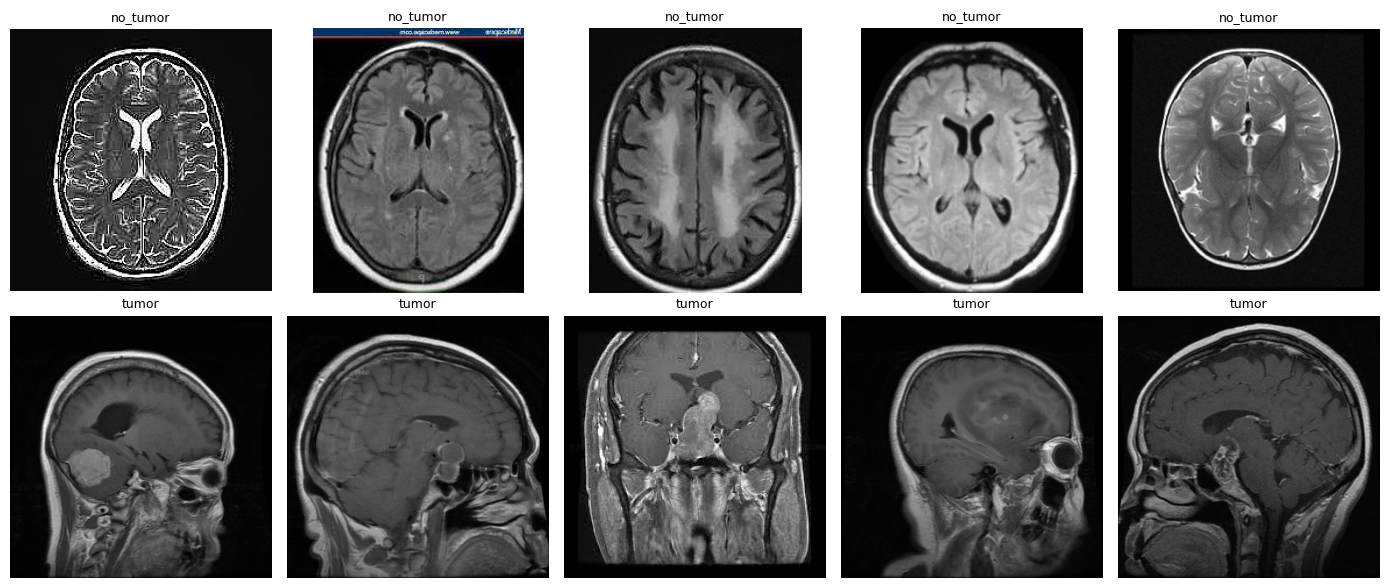

In [4]:
sample = train_df.sample(min(300, len(train_df)), random_state=0)
info = []
for p in sample['path']:
    with Image.open(p) as im:
        info.append({'w': im.size[0], 'h': im.size[1], 'mode': im.mode})
info = pd.DataFrame(info)
print(info.describe().round(0).loc[['min', '50%', 'max']])
print('Colour modes:', info['mode'].value_counts().to_dict())

fig, axes = plt.subplots(len(classes), 5, figsize=(14, 3 * len(classes)))
axes = np.atleast_2d(axes)
for r, c in enumerate(classes):
    paths = train_df[train_df.label == c]['path'].sample(5, random_state=1)
    for ax, p in zip(axes[r], paths):
        ax.imshow(Image.open(p).convert('RGB'))
        ax.set_title(c, fontsize=9)
        ax.axis('off')
plt.tight_layout()
plt.show()

## 5. Checking for Multi-Image Groups

Counts how many images share the same group id.

- **Groups with more than 1 image: 0**
- Every group has exactly 1 image (the top-10 listing is all 1s).

**Meaning:** a group-aware splitter has nothing to group on, so it behaves like a stratified random split. If the same patient or the same scan appears twice under different file names, the split cannot see it. The next cells therefore search for duplicates by **content** instead of by name.

In [5]:
g = train_df.groupby('group').size().sort_values(ascending=False)
print('Groups with more than 1 image:', (g > 1).sum())
print(g.head(10).to_string())
print(train_df[train_df['group'] == g.index[0]][['orig_class', 'file']].to_string())

Groups with more than 1 image: 0
group
Tr-pi_984.jpg    1
Tr-pi_983.jpg    1
Tr-pi_982.jpg    1
Tr-pi_981.jpg    1
Tr-pi_980.jpg    1
Tr-pi_98.jpg     1
Tr-pi_979.jpg    1
Tr-pi_978.jpg    1
Tr-pi_977.jpg    1
Tr-pi_976.jpg    1
     orig_class           file
7183  pituitary  Tr-pi_984.jpg


## 6. Finding Exact Duplicate Images (MD5 Hash)

Two files with identical bytes produce the same MD5 hash, so grouping by hash finds exact copies even when the file names differ.

$$
\text{MD5}(f_1)=\text{MD5}(f_2)\;\Rightarrow\;f_1 \text{ and } f_2 \text{ are byte-identical (collisions are practically impossible)}
$$

The helper `fingerprint` (used later) builds a 32 x 32 grey thumbnail and standardises it, so it also survives resizing, re-compression and brightness changes:

$$
z=\frac{a-\bar a}{\sigma_a+10^{-6}}
$$

**Printed results**

- Exact duplicate files: **340**
- Duplicate groups (sets of identical files): **153**
- Redundant copies = 340 - 153 = **187**

The sample listing shows identical files carrying the same original class (for example several `Tr-pi_*` pituitary files and several `Tr-no_*` no-tumour files).

In [6]:
def md5(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

def fingerprint(path, n=32):
    """32 x 32 grayscale thumbnail, standardized: robust to resizing,
    recompression, and brightness changes."""
    with Image.open(path) as im:
        im.draft('L', (n * 4, n * 4))            # fast JPEG decode
        a = np.asarray(im.convert('L').resize((n, n)), dtype=np.float32)
    return ((a - a.mean()) / (a.std() + 1e-6)).flatten()

all_df = pd.concat([train_df.assign(split='train'),
                    test_df.assign(split='test')]) if TEST_DIR else train_df.copy()
all_df['md5'] = [md5(p) for p in all_df['path']]
exact = all_df[all_df.duplicated('md5', keep=False)]
print('Exact duplicate files:', len(exact))
print('Duplicate groups (sets of identical files):', exact['md5'].nunique())
if len(exact):
    print(exact.sort_values('md5')[['orig_class', 'file', 'md5']].head(20).to_string())
    conflict = exact.groupby('md5')['label'].nunique()
    print('Identical files with DIFFERENT labels:', (conflict > 1).sum())

Exact duplicate files: 340
Duplicate groups (sets of identical files): 153
     orig_class            file                               md5
6408  pituitary   Tr-pi_286.jpg  00748c6aaa5c199b07f8fa7140fc19c1
6531  pituitary   Tr-pi_397.jpg  00748c6aaa5c199b07f8fa7140fc19c1
6431  pituitary   Tr-pi_306.jpg  008c98403b057fc344bf0a9f2e7de6c2
6279  pituitary    Tr-pi_17.jpg  008c98403b057fc344bf0a9f2e7de6c2
5974  pituitary  Tr-pi_1155.jpg  0140560cc9a91abc3e62e9e1bec6c5ea
5910  pituitary  Tr-pi_1098.jpg  0140560cc9a91abc3e62e9e1bec6c5ea
7071  pituitary   Tr-pi_883.jpg  05c3caea567ffd77caf79c12654b87e5
6569  pituitary   Tr-pi_430.jpg  05c3caea567ffd77caf79c12654b87e5
6337  pituitary   Tr-pi_221.jpg  05c3caea567ffd77caf79c12654b87e5
4838    notumor  Tr-no_1393.jpg  05fe39a899414d2dab6cad25c301b32c
5404    notumor   Tr-no_642.jpg  05fe39a899414d2dab6cad25c301b32c
5411    notumor   Tr-no_649.jpg  06c3e21e888012e7845da47b26b742e8
5598    notumor   Tr-no_817.jpg  06c3e21e888012e7845da47b26b742e8
5

## 7. Removing Duplicate Copies

`drop_duplicates('md5', keep='first')` keeps one copy of each distinct file.

$$
7200-187=7013\ \text{images remain}
$$

This matches the printed result: *Removed 187 duplicate copies; 7013 images remain*. Removing duplicates before splitting stops the same image from landing in both training and evaluation data.

In [7]:
# Keep one copy of each byte-identical file
train_df['md5'] = all_df['md5'].values[:len(train_df)]   # train rows come first in all_df
before = len(train_df)
train_df = train_df.drop_duplicates('md5', keep='first').reset_index(drop=True)
print(f'Removed {before - len(train_df)} duplicate copies; {len(train_df)} images remain')


Removed 187 duplicate copies; 7013 images remain


## 8. Train / Validation / Test Split (Stratified, Group-Aware)

`StratifiedGroupKFold(n_splits=6)` keeps the tumour / no-tumour ratio in every part and never puts one group in two parts. The first fold is used as validation, then the same procedure is applied again to what is left to carve a test set.

**Arithmetic (each fold is about 1/6 of the data)**

$$
\text{val}\approx\frac{7013}{6}=1169
$$
$$
\text{remaining}=7013-1169=5844,\qquad \text{test}\approx\frac{5844}{6}=974,\qquad \text{train}=5844-974=4870
$$

**Printed results**

- train 4870 | val 1169 | test 974
- Groups shared by train and val: **0**; by train and test: **0**
- Validation labels: tumor 889, no_tumor 280

**Caution:** because every image is its own group, "0 shared groups" is guaranteed by construction. It does **not** prove there is no leakage. The next cell checks this by image content.

In [8]:
# Validation split BY GROUP: no leaf appears in both train and val
sgkf = StratifiedGroupKFold(n_splits=6, shuffle=True, random_state=42)
tr_idx, va_idx = next(sgkf.split(train_df, train_df['label'],
                                 train_df['group']))
tr_df = train_df.iloc[tr_idx].reset_index(drop=True)
va_df = train_df.iloc[va_idx].reset_index(drop=True)
if not TEST_DIR:                                         # carve a grouped test set
    tr_idx, te_idx = next(sgkf.split(tr_df, tr_df['label'], tr_df['group']))
    tr_df, test_df = (tr_df.iloc[tr_idx].reset_index(drop=True),
                      tr_df.iloc[te_idx].reset_index(drop=True))

shared = set(tr_df.group) & set(va_df.group)
print(f'train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Groups shared by train and val:', len(shared))   # must be 0
print('Groups shared by train and test:', len(set(tr_df.group) & set(test_df.group)))
print(va_df['label'].value_counts().to_string())

train 4870 | val 1169 | test 974
Groups shared by train and val: 0
Groups shared by train and test: 0
label
tumor       889
no_tumor    280


## 9. Near-Duplicate Check Between Splits

Exact hashes miss images that are re-saved, resized or slightly re-compressed. Each image is turned into a 32 x 32 standardised vector (1024 values), and for every validation / test image the nearest training image is found using the mean absolute difference:

$$
d(a,b)=\frac{1}{1024}\sum_{i=1}^{1024}\left|a_i-b_i\right|
$$

An image is called a **near-duplicate** if $d<0.10$. The closest test distances printed are all 0, i.e. identical thumbnails.

**Printed results**

| Split | Near-duplicates in train | Share |
|---|---|---|
| Test | 230 of 974 | 230 / 974 = 23.6% |
| Validation | 260 of 1169 | 260 / 1169 = 22.2% |

These images are removed from validation and test (never from train):

$$
974-230=744\ (\text{test}),\qquad 1169-260=909\ (\text{val})
$$

**Label counts after removal**

- Validation: tumor 840, no_tumor 69 (no_tumor fell from 280 to 69, so 211 of 280 = 75.4% of the healthy validation images had a near-twin in train)
- Test: tumor 687, no_tumor 57

**Two consequences**

1. Without this cleaning, about one in four evaluation images would have been a memorised training image, which inflates every score.
2. Prevalence shift: tumour is 3703 / 4870 = 76.0% of train but 687 / 744 = 92.3% of test. This matters for PPV and NPV later.

Fingerprints done in 17s
Test images with a near-duplicate in train: 230 of 974
Val images with a near-duplicate in train:  260 of 1169
Closest test distances: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


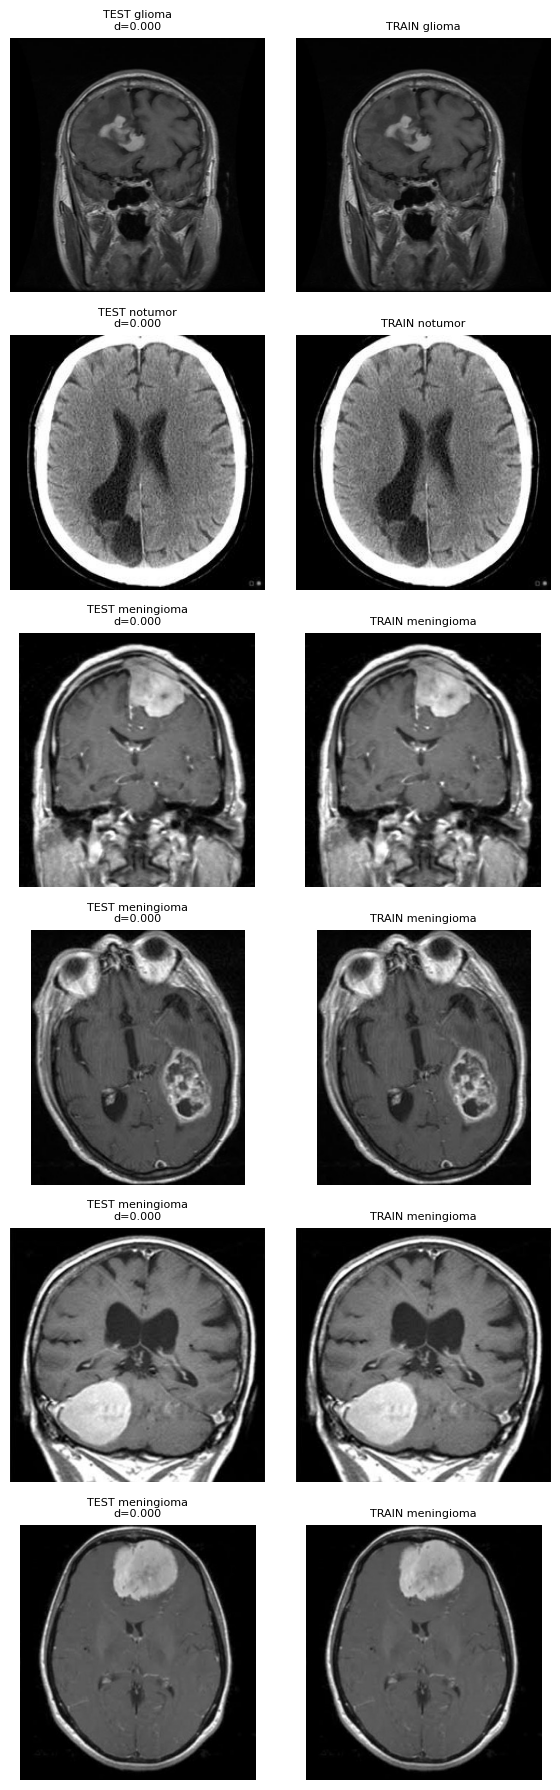

After removal: train 4870 | val 909 | test 744
Val labels: {'tumor': 840, 'no_tumor': 69} | Test labels: {'tumor': 687, 'no_tumor': 57}


In [9]:
# Near-duplicate check between the carved splits (needed because TEST_DIR = None)
def fp_matrix(df):
    return torch.tensor(np.stack([fingerprint(p) for p in df['path']]),
                        dtype=torch.float32, device=device)

def nearest(A, B, chunk=512):
    """For each row of A: mean absolute difference to its closest row of B, and that row's index."""
    dists, idxs = [], []
    for i in range(0, len(A), chunk):
        d = torch.cdist(A[i:i + chunk], B, p=1) / A.shape[1]
        m, j = d.min(1)
        dists.append(m.cpu())
        idxs.append(j.cpu())
    return torch.cat(dists).numpy(), torch.cat(idxs).numpy()

t0 = time.time()
FP_tr, FP_va, FP_te = fp_matrix(tr_df), fp_matrix(va_df), fp_matrix(test_df)
print(f'Fingerprints done in {time.time() - t0:.0f}s')

d_te, j_te = nearest(FP_te, FP_tr)
d_va, j_va = nearest(FP_va, FP_tr)
near_te, near_va = d_te < 0.10, d_va < 0.10
print(f'Test images with a near-duplicate in train: {near_te.sum()} of {len(test_df)}')
print(f'Val images with a near-duplicate in train:  {near_va.sum()} of {len(va_df)}')
print('Closest test distances:', np.sort(d_te)[:10].round(3))

# Inspect the closest pairs BEFORE deleting anything
order = np.argsort(d_te)[:6]
fig, axes = plt.subplots(len(order), 2, figsize=(6, 3 * len(order)))
for r, k in enumerate(order):
    a, b = test_df.iloc[k], tr_df.iloc[j_te[k]]
    axes[r, 0].imshow(Image.open(a['path']).convert('RGB'))
    axes[r, 0].set_title(f"TEST {a['orig_class']}\nd={d_te[k]:.3f}", fontsize=8)
    axes[r, 1].imshow(Image.open(b['path']).convert('RGB'))
    axes[r, 1].set_title(f"TRAIN {b['orig_class']}", fontsize=8)
    axes[r, 0].axis('off')
    axes[r, 1].axis('off')
plt.tight_layout()
plt.show()
# Remove val/test images that have a near-duplicate in train (they would inflate the scores)
test_df = test_df[~near_te].reset_index(drop=True)
va_df = va_df[~near_va].reset_index(drop=True)
print(f'After removal: train {len(tr_df)} | val {len(va_df)} | test {len(test_df)}')
print('Val labels:', va_df['label'].value_counts().to_dict(),
      '| Test labels:', test_df['label'].value_counts().to_dict())


## 10. Pre-processing, Augmentation and Datasets

**Training transforms** (random, to reduce over-fitting): grey-scale to 3 channels, random resized crop (scale 0.8 to 1.0) to 224 x 224, horizontal and vertical flips, rotation up to 20 degrees, and brightness / contrast jitter of 0.15. Hue and saturation are deliberately not changed.

**Evaluation transforms** (deterministic): grey-scale to 3 channels, resize to 224 x 224, normalise.

**Normalisation** with the ImageNet statistics the backbone was pretrained with, per channel:

$$
x'_c=\frac{x_c-\mu_c}{\sigma_c},\qquad \mu=(0.485,\,0.456,\,0.406),\quad \sigma=(0.229,\,0.224,\,0.225)
$$

**Printed results**

- train 4870 | val 909 | test 744
- Class order: `['no_tumor', 'tumor']`, so index 0 = no_tumor and index 1 = tumor (used by every later cell).

In [10]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
to_rgb = [transforms.Grayscale(num_output_channels=3)] if GRAYSCALE else []

train_tf = transforms.Compose(to_rgb + [
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),   # no hue/saturation: colour is disease evidence
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose(to_rgb + [
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ImageTable(Dataset):
    def __init__(self, df, tf):
        self.paths = df['path'].tolist()
        self.y = df['label'].map({c: i for i, c in enumerate(classes)}).tolist()
        self.tf = tf
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i])
        img = img.convert('L' if GRAYSCALE else 'RGB')
        return self.tf(img), self.y[i]

train_ds = ImageTable(tr_df, train_tf)
val_ds = ImageTable(va_df, eval_tf)
test_ds = ImageTable(test_df, eval_tf)
print(f'train {len(train_ds)} | val {len(val_ds)} | test {len(test_ds)}')
print('Class order:', classes)

train 4870 | val 909 | test 744
Class order: ['no_tumor', 'tumor']


## 11. Class Weights for the Imbalanced Training Set

The training set has far more tumour images than healthy ones. To stop the model from simply favouring the majority class, each class gets a weight that is inversely proportional to its size:

$$
w_c=\frac{N}{K\cdot n_c}
$$

where $N$ = number of training images, $K$ = number of classes, $n_c$ = images in class $c$.

**Working with the notebook values** ($N=4870,\;K=2$)

$$
w_{\text{no\_tumor}}=\frac{4870}{2\times1167}=\frac{4870}{2334}=2.087
$$
$$
w_{\text{tumor}}=\frac{4870}{2\times3703}=\frac{4870}{7406}=0.658
$$

**Check:** each class now contributes the same total weight:

$$
1167\times2.087\approx2435,\qquad 3703\times0.658\approx2435,\qquad \frac{N}{K}=\frac{4870}{2}=2435
$$

A healthy image therefore counts about $2.087/0.658\approx3.2$ times as much as a tumour image in the loss.

**Weighted cross-entropy** (what `F.cross_entropy(..., weight=loss_w)` computes, with mean reduction):

$$
\mathcal{L}=-\frac{\sum_i w_{y_i}\,\log p_{i,y_i}}{\sum_i w_{y_i}}
$$

`USE_SAMPLER = False` means the weights are applied in the loss. Setting it to `True` instead draws balanced batches with $P(i)\propto 1/n_{c(i)}$ and switches the loss weights off, so the imbalance is never corrected twice.

In [11]:
n_c = np.bincount(train_ds.y, minlength=len(classes))
class_w = len(train_ds) / (len(classes) * n_c)        # N / (K * n_c)
print('Images per class in train:', dict(zip(classes, n_c)))
print('Class weights:', dict(zip(classes, class_w.round(3))))
loss_w = torch.tensor(class_w, dtype=torch.float32, device=device)

USE_SAMPLER = False     # try True later: balanced batches instead of weighted loss
if USE_SAMPLER:
    sample_w = class_w[train_ds.y]                     # P(i) ~ 1 / n_class(i)
    sampler = WeightedRandomSampler(sample_w, len(sample_w), replacement=True)
    train_dl = DataLoader(train_ds, 32, sampler=sampler, num_workers=2)
    loss_w = None
else:
    train_dl = DataLoader(train_ds, 32, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, 64, num_workers=2)
test_dl = DataLoader(test_ds, 64, num_workers=2)

Images per class in train: {'no_tumor': np.int64(1167), 'tumor': np.int64(3703)}
Class weights: {'no_tumor': np.float64(2.087), 'tumor': np.float64(0.658)}


## 12. Loading the Pretrained ResNet-18

`find_weights` looks for a local ImageNet checkpoint (no internet is needed in this Kaggle session) and `load_local` copies the matching tensors into the model. `build_model` then:

1. replaces the final layer with `Linear(512, 2)`,
2. **freezes** every backbone parameter,
3. un-freezes only the new head.

**Printed results**

- Weight file used: `resnet18-f37072fd.pth`
- Loaded 102 tensors, nothing skipped, no missing keys
- Trainable parameters = **1026**

$$
\underbrace{512\times2}_{\text{weights}}+\underbrace{2}_{\text{biases}}=1024+2=1026
$$

The two output logits $z_0,z_1$ are turned into probabilities with the softmax:

$$
p_c=\frac{e^{z_c}}{e^{z_0}+e^{z_1}}
$$

In [12]:
import glob

def find_weights(name):
    """Search /kaggle/input (recursively) and the torch cache for a .pth/.pt file of this backbone."""
    key = name.replace('_', '').replace('-', '').lower()
    roots = ['/kaggle/input', os.path.expanduser('~/.cache/torch/hub/checkpoints')]
    hits = []
    for root in roots:
        for dp, _, fs in os.walk(root):
            for f in fs:
                if f.lower().endswith(('.pth', '.pt')):
                    full = os.path.join(dp, f)
                    if key in full.lower().replace('_', '').replace('-', ''):
                        hits.append(full)
    # prefer the official ImageNet file (e.g. resnet18-f37072fd.pth) over fine-tuned ones
    pref = name.replace('_', '') + '-'
    hits.sort(key=lambda p: (not os.path.basename(p).lower().startswith(pref), p))
    print('Weight files found:', hits)
    if not hits:
        mdir = '/kaggle/input/models'
        print('Nothing matched. /kaggle/input contains:', os.listdir('/kaggle/input')
              if os.path.isdir('/kaggle/input') else 'N/A')
        if os.path.isdir(mdir):
            for dp, _, fs in os.walk(mdir):
                for f in fs:
                    print('  model file:', os.path.join(dp, f))
    return hits[0] if hits else None

def load_local(m, path):
    """Load a .pth/.pt file into model m, skipping any tensor whose shape does not match
    (e.g. the 1000-class or 6-class fc layer of a different checkpoint)."""
    obj = torch.load(path, map_location='cpu', weights_only=False)
    if isinstance(obj, nn.Module):                 # file holds a whole model
        obj = obj.state_dict()
    if isinstance(obj, dict) and 'state_dict' in obj:
        obj = obj['state_dict']
    obj = {k.replace('module.', ''): v for k, v in obj.items()}
    own = m.state_dict()
    ok = {k: v for k, v in obj.items() if k in own and own[k].shape == v.shape}
    skipped = [k for k in obj if k not in ok]
    result = m.load_state_dict(ok, strict=False)
    print('Loaded', len(ok), 'tensors from', os.path.basename(path))
    print('Skipped (shape/name mismatch):', skipped)
    print('Missing keys:', result.missing_keys)
    return m

def get_backbone(name, ctor, weights_enum):
    local = find_weights(name)
    if local:
        return load_local(ctor(weights=None), local)
    try:                                           # needs internet
        return ctor(weights=weights_enum.DEFAULT)
    except Exception as e:
        raise RuntimeError(
            f'No local {name} weights found and the download failed ({type(e).__name__}). '
            f'Fix: in the Kaggle sidebar click "Add Input" -> Models -> search "{name}" '
            f'(PyTorch) and add it, OR turn on Settings -> Internet.') from None

def build_model(name, n_classes):
    if name == 'resnet18':
        m = get_backbone(name, models.resnet18, models.ResNet18_Weights)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'resnet50':
        m = get_backbone(name, models.resnet50, models.ResNet50_Weights)
        m.fc = nn.Linear(m.fc.in_features, n_classes)
        body, head, last = m, m.fc, m.layer4
    elif name == 'efficientnet_b0':
        m = get_backbone(name, models.efficientnet_b0, models.EfficientNet_B0_Weights)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, n_classes)
        body, head, last = m, m.classifier, m.features[-1]
    else:
        raise ValueError(name)
    for p in body.parameters():
        p.requires_grad = False
    for p in head.parameters():
        p.requires_grad = True
    return m.to(device), head, last

model, head, last_block = build_model(BACKBONE, len(classes))
print(BACKBONE, 'trainable:',
      sum(p.numel() for p in model.parameters() if p.requires_grad))

Weight files found: ['/kaggle/input/models/umarkhan360/resnet-18/pytorch/default/1/resnet18-f37072fd.pth', '/kaggle/input/models/umarkhan360/resnet-pt/pytorch/default/1/resnet18_intel.pt']
Loaded 102 tensors from resnet18-f37072fd.pth
Skipped (shape/name mismatch): []
Missing keys: []
resnet18 trainable: 1026


## 13. Two-Phase Training

**Phase 1 (head only, 2 epochs, lr = 1e-3):** only the new 1026 parameters learn, so the pretrained features are untouched.
**Phase 2 (fine-tune, 3 epochs):** the last residual block (`layer4`) is un-frozen with a small learning rate (1e-4) while the head keeps 1e-3.

Each epoch minimises the weighted cross-entropy from Section 11 with the Adam optimiser. The model is scored on the validation set with **macro-F1** (not accuracy), and the best weights are restored at the end of each phase.

$$
\text{F1}_c=\frac{2\,P_c\,R_c}{P_c+R_c},\qquad \text{macro-F1}=\frac{1}{K}\sum_{c=1}^{K}\text{F1}_c
$$

Macro-F1 gives each class equal importance, so a good score on the large tumour class cannot hide a poor score on the small healthy class.

**Printed validation macro-F1**

| Phase | Epoch | Macro-F1 |
|---|---|---|
| 1 | 1 | 0.903 |
| 1 | 2 | 0.846 |
| 2 | 1 | **0.924** (best) |
| 2 | 2 | 0.907 |
| 2 | 3 | 0.913 |

Fine-tuning `layer4` raises the best score from 0.903 to 0.924. The scores move up and down between epochs because the validation set has only 69 healthy images, so a few mistakes change the score noticeably.

In [13]:
def predict(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        for xb, yb in loader:
            probs.append(F.softmax(model(xb.to(device)), 1).cpu())
            ys.append(yb)
    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

def fit(model, params, epochs, lr):
    opt = torch.optim.Adam(params, lr=lr)
    best, best_state = -1, None
    for ep in range(epochs):
        model.train()
        t0 = time.time()
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            loss = F.cross_entropy(model(xb), yb, weight=loss_w)
            opt.zero_grad()
            loss.backward()
            opt.step()
        p, y = predict(model, val_dl)
        macro = f1_score(y, p.argmax(1), average='macro')      # not accuracy
        if macro > best:
            best, best_state = macro, copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: val macro-F1 {macro:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)
    return best

print('Phase 1: head only')
fit(model, head.parameters(), epochs=2, lr=1e-3)
print('Phase 2: fine-tune the last block')
for p in last_block.parameters():
    p.requires_grad = True
fit(model, [{'params': last_block.parameters(), 'lr': 1e-4},
            {'params': head.parameters(), 'lr': 1e-3}], epochs=3, lr=1e-3)

Phase 1: head only
epoch 1: val macro-F1 0.903 (348s)
epoch 2: val macro-F1 0.846 (360s)
Phase 2: fine-tune the last block
epoch 1: val macro-F1 0.924 (459s)
epoch 2: val macro-F1 0.907 (454s)
epoch 3: val macro-F1 0.913 (458s)


0.9239849475143593

## 14. Test-Set Evaluation

The final model is run once on the untouched test set (744 images: 57 no_tumor, 687 tumor) with the default decision rule $\hat y=\arg\max_c p_c$.

**Metric definitions**

$$
P=\frac{TP}{TP+FP},\qquad R=\frac{TP}{TP+FN},\qquad F1=\frac{2PR}{P+R}
$$

**Printed results**

| Class | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| no_tumor | 0.962 | 0.877 | 0.917 | 57 |
| tumor | 0.990 | 0.997 | 0.993 | 687 |

**Check of the F1 values**

$$
F1_{\text{no\_tumor}}=\frac{2(0.962)(0.877)}{0.962+0.877}=\frac{1.6875}{1.839}=0.917
$$

**Macro vs weighted averages**

$$
\text{macro-F1}=\frac{0.917+0.993}{2}=0.955
$$
$$
\text{weighted-F1}=\frac{57(0.917)+687(0.993)}{744}=\frac{734.5}{744}=0.987\approx0.988
$$

$$
\text{accuracy}=0.988\;\Rightarrow\;\approx735\text{ of }744\text{ correct}
$$

**Reading the result:** accuracy and weighted-F1 (0.988) look excellent, but they are dominated by the 687 tumour images. Macro-F1 (0.955) shows the weaker class: only 87.7% of healthy scans are recognised as healthy (about 50 of 57).

*(The confusion-matrix counts implied by the reported metrics are about TN = 50, FP = 7, FN = 2, TP = 685; the plot below shows the exact values.)*

              precision    recall  f1-score   support

    no_tumor      0.962     0.877     0.917        57
       tumor      0.990     0.997     0.993       687

    accuracy                          0.988       744
   macro avg      0.976     0.937     0.955       744
weighted avg      0.988     0.988     0.988       744

Macro-F1: 0.955


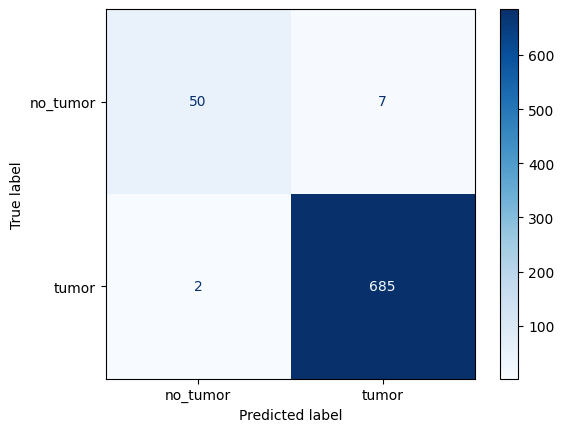

In [14]:
p_test, y_test = predict(model, test_dl)
pred = p_test.argmax(1)
print(classification_report(y_test, pred, target_names=classes, digits=3))
print('Macro-F1:', round(f1_score(y_test, pred, average='macro'), 3))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred),
                       display_labels=classes).plot(cmap='Blues')
plt.show()

## 15. Choosing a Decision Threshold for a Target Recall

In screening, **missing a tumour (a false negative) is the costly error**. Instead of using 0.5, the threshold $t$ is chosen **on the validation set** as the highest value whose recall is at least `TARGET_RECALL = 0.95`, then applied unchanged to the test set. Choosing it on validation avoids tuning on the test data.

**Metric definitions** (tumour = positive class)

$$
\text{Sensitivity}=\frac{TP}{TP+FN},\quad
\text{Specificity}=\frac{TN}{TN+FP},\quad
\text{PPV}=\frac{TP}{TP+FP},\quad
\text{NPV}=\frac{TN}{TN+FN}
$$

**Printed results**

- Threshold chosen: **t = 0.986** (predict tumour only when $p_{\text{tumor}}\ge0.986$)
- TP = 668, FN = 19, TN = 55, FP = 2
- Test prevalence = (668 + 19) / 744 = 687 / 744 = **0.923**
- Test AUC = **0.994**

**Working**

$$
\text{Sensitivity}=\frac{668}{668+19}=\frac{668}{687}=0.972\;(\ge0.95\ \checkmark)
$$
$$
\text{Specificity}=\frac{55}{55+2}=\frac{55}{57}=0.965
$$
$$
\text{PPV}=\frac{668}{668+2}=\frac{668}{670}=0.997
$$
$$
\text{NPV}=\frac{55}{55+19}=\frac{55}{74}=0.743
$$

**Interpretation:** the validation-chosen threshold keeps test sensitivity above the 0.95 target. The PPV is very high mainly because tumour prevalence is 92%. The NPV is much lower (0.743): when the model says "no tumour", about 1 in 4 of those calls is wrong. PPV and NPV depend on prevalence, so they would change if the model were used on a population with fewer tumours (see Question 4).

In [15]:
if len(classes) == 2:
    pos = classes.index(POSITIVE)
    p_val, y_val = predict(model, val_dl)
    fpr, tpr, thr = roc_curve(y_val == pos, p_val[:, pos])
    t = thr[np.argmax(tpr >= TARGET_RECALL)]     # highest t reaching target
    print(f'Threshold chosen on VALIDATION for recall >= {TARGET_RECALL}: '
          f'{t:.3f}')

    s = p_test[:, pos]
    yp, yt = s >= t, y_test == pos
    tp, fn = (yp & yt).sum(), (~yp & yt).sum()
    tn, fp = (~yp & ~yt).sum(), (yp & ~yt).sum()
    print(f'TP {tp} | FN {fn} | TN {tn} | FP {fp}')
    print(f'Test prevalence of {POSITIVE}: {yt.mean():.3f}')
    print(f'Test AUC {roc_auc_score(yt, s):.3f}')
    print(f'Sensitivity {tp / (tp + fn):.3f}   Specificity {tn / (tn + fp):.3f}'
          f'   PPV {tp / max(tp + fp, 1):.3f}')

Threshold chosen on VALIDATION for recall >= 0.95: 0.986
TP 668 | FN 19 | TN 55 | FP 2
Test prevalence of tumor: 0.923
Test AUC 0.994
Sensitivity 0.972   Specificity 0.965   PPV 0.997


## 16. Grad-CAM: Which Pixels Drive the Decision?

Grad-CAM produces a heat-map showing where the last convolutional block looked when scoring a class. For feature map $A^k$ of the last block ($Z$ = number of spatial positions) and class score $y^c$:

$$
\alpha_k^c=\frac{1}{Z}\sum_i\sum_j\frac{\partial y^c}{\partial A^k_{ij}}
$$
$$
L^c_{\text{Grad-CAM}}=\text{ReLU}\!\left(\sum_k \alpha_k^c\,A^k\right)
$$

In the code: `alpha = grads.mean(dim=(2,3))` is the first equation, and `relu((alpha * acts).sum(1))` is the second. The map is up-sampled to 224 x 224, divided by its maximum so it lies in [0, 1], and drawn over the image.

All parameters are set to `requires_grad = True` so gradients flow back to `layer4`. The cell shows 3 correct and 3 wrong test predictions (title: true class, predicted class, original folder).

**What to look for:** a trustworthy model highlights the brain region or the lesion, not the image border, corner text or other artefacts.

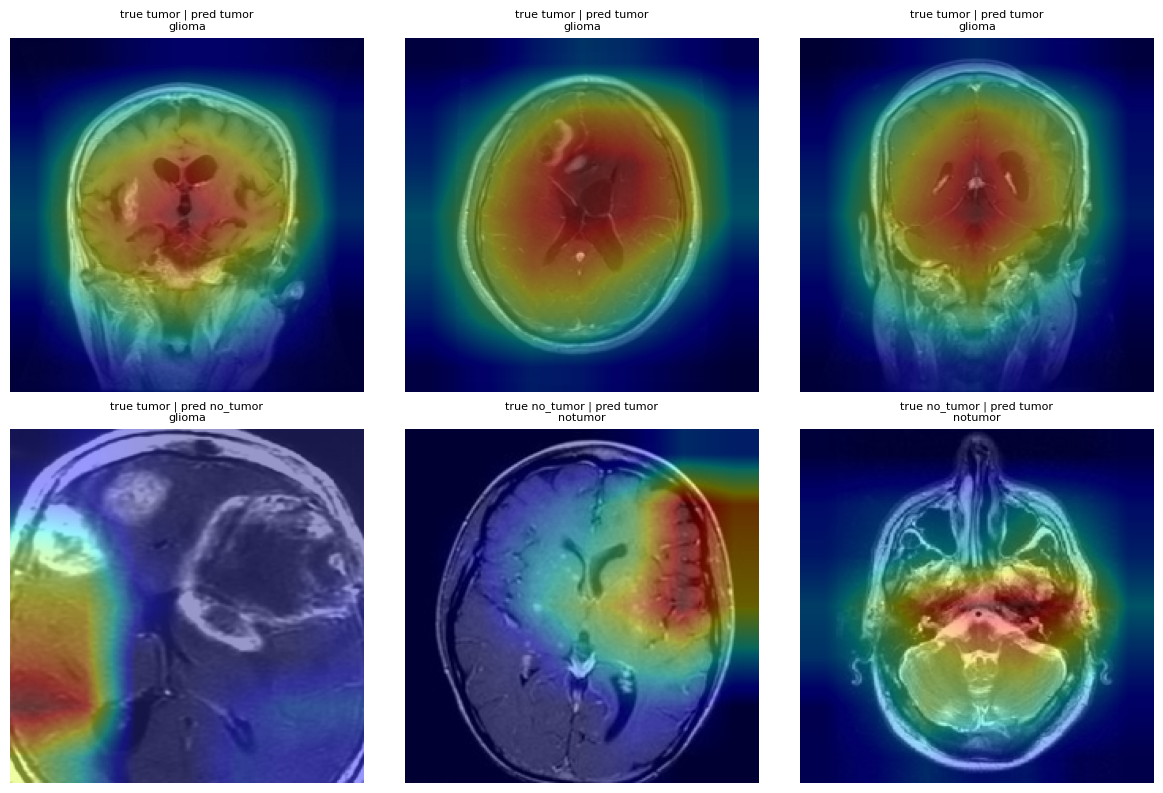

In [16]:
class GradCAM:
    def __init__(self, model, layer):
        self.model, self.acts, self.grads = model, None, None
        layer.register_forward_hook(self._save_act)
        layer.register_full_backward_hook(self._save_grad)
    def _save_act(self, m, i, o):
        self.acts = o.detach()
    def _save_grad(self, m, gi, go):
        self.grads = go[0].detach()
    def __call__(self, x, cls=None):
        self.model.eval()
        x = x.unsqueeze(0).to(device).requires_grad_(True)
        logits = self.model(x)
        cls = int(logits.argmax()) if cls is None else cls
        self.model.zero_grad()
        logits[0, cls].backward()
        alpha = self.grads.mean(dim=(2, 3), keepdim=True)      # (1/Z) sum dy/dA
        cam = F.relu((alpha * self.acts).sum(1)).squeeze()     # ReLU(sum a*A)
        cam = F.interpolate(cam[None, None], size=x.shape[-2:],
                            mode='bilinear').squeeze()
        return (cam / (cam.max() + 1e-8)).cpu().numpy(), cls

for p in model.parameters():
    p.requires_grad = True
cam = GradCAM(model, last_block)
wrong = np.where(pred != y_test)[0][:3].tolist()
right = np.where(pred == y_test)[0][:3].tolist()
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
for ax, i in zip(axes.flat, right + wrong):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}\n{test_df.orig_class[i]}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

## 17. Grad-CAM on a Balanced Selection of Examples

A more systematic version of the previous cell. A fixed random generator (`default_rng(0)`) selects:

- **one correctly classified image from each original folder** (glioma, meningioma, notumor, pituitary), giving up to 4 images,
- **up to 4 misclassified images**,

so up to 4 + 4 = 8 panels are drawn in a 2 x 4 grid. Looking at every original sub-type shows whether the model attends to the right anatomy for each tumour type, and the error panels show what misled it.

Any bright region that is not anatomy would be a warning sign of shortcut learning (see Question 6).

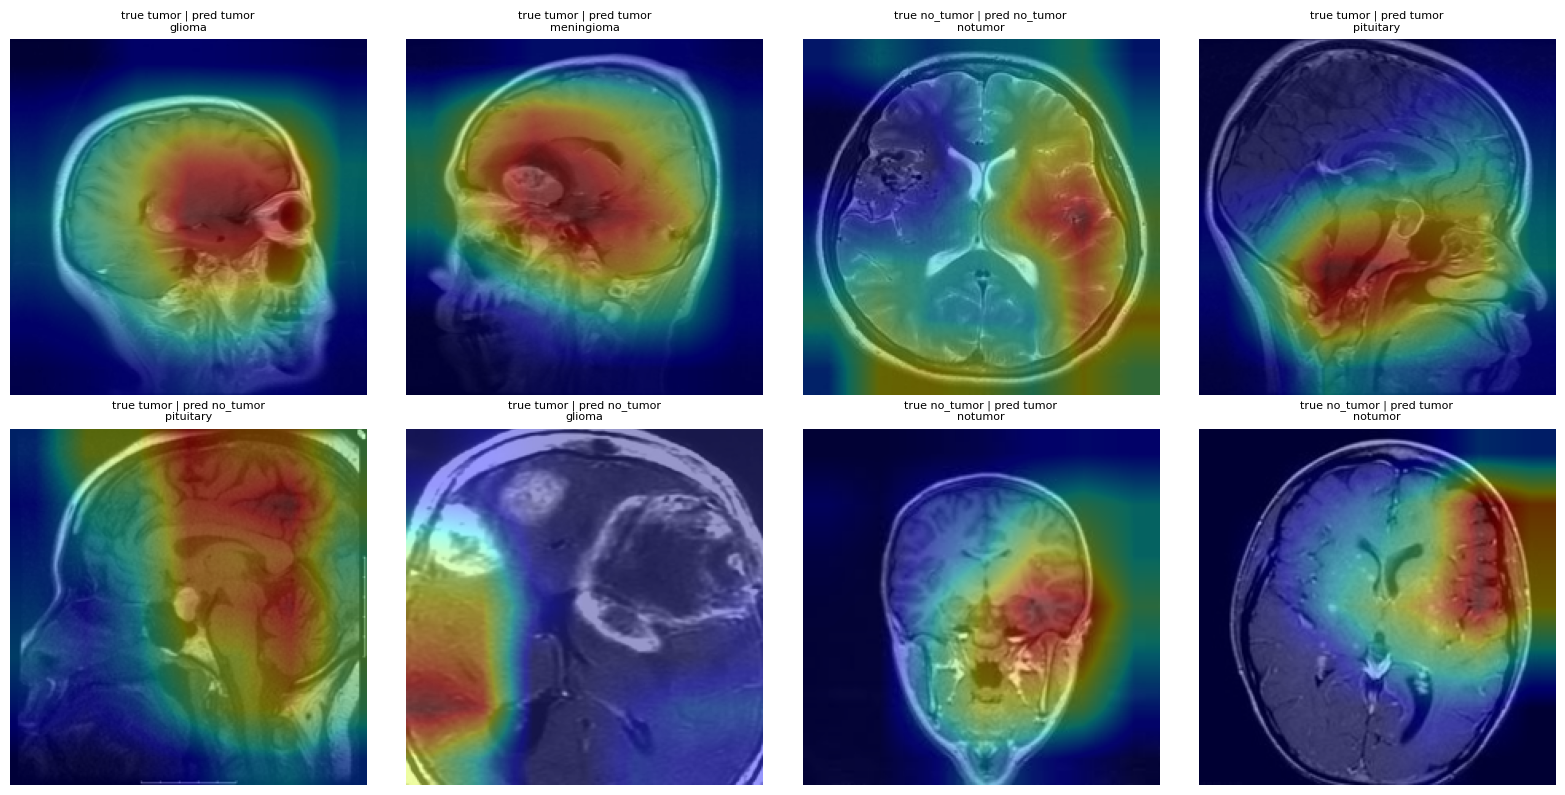

In [17]:
rng = np.random.default_rng(0)
orig = test_df['orig_class'].values
right_pool = np.where(pred == y_test)[0]
wrong_pool = np.where(pred != y_test)[0]
# one correctly classified example per original folder, plus up to 4 mistakes
right = [int(rng.choice(right_pool[orig[right_pool] == c]))
         for c in sorted(set(orig)) if (orig[right_pool] == c).any()]
wrong = rng.choice(wrong_pool, size=min(4, len(wrong_pool)), replace=False).tolist()
idx = right + wrong

fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax in axes.flat:
    ax.axis('off')
for ax, i in zip(axes.flat, idx):
    x, y = test_ds[i]
    heat, c = cam(x)
    img = Image.open(test_ds.paths[i]).convert('RGB').resize((IMG_SIZE,) * 2)
    ax.imshow(img)
    ax.imshow(heat, cmap='jet', alpha=0.4)
    ax.set_title(f'true {classes[y]} | pred {classes[c]}\n{test_df.orig_class[i]}', fontsize=8)
plt.tight_layout()
plt.show()


## 18. Saving the Model

The checkpoint stores everything needed to reload and use the model later:

- `state_dict`: all learned weights
- `classes`: `['no_tumor', 'tumor']` (output index order)
- `backbone`: `resnet18`
- `img_size`: 224
- `grayscale`: `True` (pre-processing must match training)

Output file: `week6_model.pt`. Remember that the chosen operating threshold (**0.986**) is not stored in the file and must be applied separately at prediction time.

In [18]:
torch.save({'state_dict': model.state_dict(), 'classes': classes,
            'backbone': BACKBONE, 'img_size': IMG_SIZE,
            'grayscale': GRAYSCALE}, '/kaggle/working/week6_model.pt')
print('Saved week6_model.pt')

Saved week6_model.pt


# Answers to the Review Questions

## 1. Why does a random split of chest X-rays overestimate performance?

A chest X-ray dataset usually contains **several images per patient** (follow-up scans, repeated views) and many near-identical images from the same scanner or hospital. A random split places some of a patient's images in training and others in testing. The network then recognises **the patient or the scanner/site fingerprint** (body shape, implants, equipment artefacts, image style) instead of learning the disease, and it is "tested" on images it has effectively already seen. The result is **data leakage** and optimistic accuracy, sensitivity and AUC that will not hold on new patients or new hospitals.

The fix is to split **by patient** (group-aware split, e.g. `StratifiedGroupKFold`) and, ideally, to test on an external hospital.

**Evidence in this notebook:** with no patient id, a normal split looked clean ("0 shared groups"), yet the content check found

$$
\frac{230}{974}=23.6\%\ \text{of test images and}\ \frac{260}{1169}=22.2\%\ \text{of validation images}
$$

had a near-duplicate in the training set. Without removing them, almost a quarter of the evaluation would have been memorised images.

---

## 2. Class weights for 900 and 100 training images, $w_c=N/(K\,n_c)$

$$
N=900+100=1000,\qquad K=2
$$
$$
w_{900}=\frac{1000}{2\times900}=\frac{1000}{1800}=0.556
$$
$$
w_{100}=\frac{1000}{2\times100}=\frac{1000}{200}=5.0
$$

**Check:** each class contributes the same total weight, $900\times0.556=500$ and $100\times5=500$ (both equal $N/K=500$). The minority class gets 5.0 / 0.556 = 9 times the weight, which is exactly the size ratio 900 / 100 = 9.

---

## 3. Focal loss with $\gamma=2$ and $p_t=0.8$

Focal loss multiplies the cross-entropy by a modulating factor:

$$
FL(p_t)=-(1-p_t)^{\gamma}\log(p_t)
$$

so the down-weighting factor relative to cross-entropy is

$$
(1-p_t)^{\gamma}=(1-0.8)^2=0.2^2=0.04
$$

The example's loss is **multiplied by 0.04**, i.e. it is down-weighted by a factor of **1 / 0.04 = 25** (it counts 25 times less than under plain cross-entropy). For comparison, a very hard example with $p_t=0.2$ gets $(0.8)^2=0.64$, so easy examples are suppressed far more than hard ones.

*(Loss values: CE = $-\ln0.8=0.223$, FL = $0.04\times0.223=0.0089$.)*

---

## 4. PPV with sensitivity 0.90, specificity 0.95, prevalence 2%

Use a hypothetical population of 10,000 people (any size gives the same ratio):

- Diseased = $0.02\times10000=200$; healthy = $9800$
- $TP=\text{sensitivity}\times200=0.90\times200=180$
- $FP=(1-\text{specificity})\times9800=0.05\times9800=490$

$$
\text{PPV}=\frac{TP}{TP+FP}=\frac{180}{180+490}=\frac{180}{670}=0.269
$$

Equivalent Bayes form:

$$
\text{PPV}=\frac{0.90(0.02)}{0.90(0.02)+0.05(0.98)}=\frac{0.018}{0.018+0.049}=\frac{0.018}{0.067}=0.269
$$

**PPV is about 26.9%.** Although the test looks excellent, fewer than 3 in 10 positive results are real because the disease is rare. This is why PPV must be reported with the prevalence it was measured at (in this notebook PPV was 0.997 only because test prevalence was 92%).

---

## 5. When is macro-F1 a better selection metric than weighted F1?

- **Macro-F1** averages the per-class F1 scores with equal weight. **Weighted F1** averages them by class size, so the majority class dominates.
- Macro-F1 is the better choice when **classes are imbalanced and the minority class matters as much as (or more than) the majority**, e.g. rare disease, healthy vs tumour, or any case where missing the small class is costly. It stops a model from looking good by predicting the big class well.
- It is also preferable for **model/epoch selection under a shifting class mix** (train, validation and test prevalences differ), because it does not depend on how common each class happens to be.
- Weighted F1 is better only when the **deployment population has the same class mix** and overall per-sample performance is what matters.

**Evidence in this notebook (test set):**

$$
\text{weighted-F1}=\frac{57(0.917)+687(0.993)}{744}\approx0.988,\qquad
\text{macro-F1}=\frac{0.917+0.993}{2}=0.955
$$

Weighted F1 hides the weaker healthy class (recall 0.877, only 57 images), while macro-F1 exposes it. That is why the training loop selects the best epoch by macro-F1.

---

## 6. Grad-CAM highlights a hospital label in the corner of the X-rays. What next?

This is **shortcut learning**: the model uses a non-clinical cue (a hospital tag) that correlates with the label (for example one hospital sends more disease cases), so its metrics are not trustworthy even if they are high. Steps:

1. **Do not deploy or trust the reported performance.** Treat the current results as confounded.
2. **Confirm the problem:** run Grad-CAM on many images (correct and wrong) and measure how often the corner is highlighted. Test directly by masking or removing the label region and checking whether predictions or metrics drop sharply.
3. **Check the confound in the data:** tabulate class vs hospital / marker. If the label predicts the diagnosis, the dataset itself is biased.
4. **Remove the cue:** crop or in-paint the text and markers, normalise image borders, and add augmentation such as random crops and random masking so position and text cannot be used.
5. **Fix the data and the split:** balance classes across hospitals where possible, and evaluate with a **hospital-level (or patient-level) split** or an external test set from a site not seen in training.
6. **Retrain and re-check:** re-run Grad-CAM to see whether attention now falls on the lungs or the anatomy, and compare the metrics. A large drop confirms the shortcut was inflating performance.
7. **Involve clinical experts** to review the heat-maps and the corrected model before any use.
